###**Objetivos**

Uma das coisas mais legais que temos no Brasil é o acesso a dados disponibilizados por fontes oficiais.

Com todos os desafios que nosso país enfrenta, qualquer pessoa com um pouco de boa vontade pode ter acesso a um grande número de datasets que podem servir como fonte de estudo e até mesmo uma importante fonte de informação independente sobre os mais variados assuntos de nosso país.

O portal brasileiro de dados aberto é sem dúvida alguma um grande parque de diversão para quem gosta de analisar dados

Neste notebook resolvi pegar os dados dos candidadtos às eleições do ano de 2022. O foco central foram os candidatos à Presidência da República e Deputado Federal

In [66]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

sns.set()

###**Importando os dados**

In [67]:
temp = ['SQ_CANDIDATO', 'NM_CANDIDATO','NM_TIPO_ELEICAO', 'SG_UE', 'DS_CARGO', 'DS_SITUACAO_CANDIDATURA', 'NM_UE', 'SG_PARTIDO', 'DS_ESTADO_CIVIL', 'DS_GENERO', 'DS_GRAU_INSTRUCAO', 'DS_COR_RACA']
bens = ['SQ_CANDIDATO', 'ANO_ELEICAO', 'DS_TIPO_BEM_CANDIDATO', 'VR_BEM_CANDIDATO']
df = pd.read_csv('bem_candidato_2022_BRASIL.csv', encoding='ISO-8859-1', sep=';')
df_cand = pd.read_csv('bem_candidato_2022_BRASIL.csv', encoding='ISO-8859-1', sep=';', usecols=bens)
df_bens = pd.read_csv('consulta_cand_2022_BRASIL.csv', encoding='ISO-8859-1', sep=';', usecols=temp)

###**Situação dos candidatos**

Selecionei apenas candidatos que estavam aptos ou cadastrados

Existem candidatos que estão com status de inapto. Pelo sim pelo não, resolvi não perder tempo tentando entender o porquê da situação e acabei filtrando apenas os candidatos que estão com status de **Apto** ou **Cadastrado**

In [68]:
(df_bens['DS_SITUACAO_CANDIDATURA'].value_counts(normalize=True).round(2)) * 100

DS_SITUACAO_CANDIDATURA
APTO      90.0
INAPTO    10.0
Name: proportion, dtype: float64

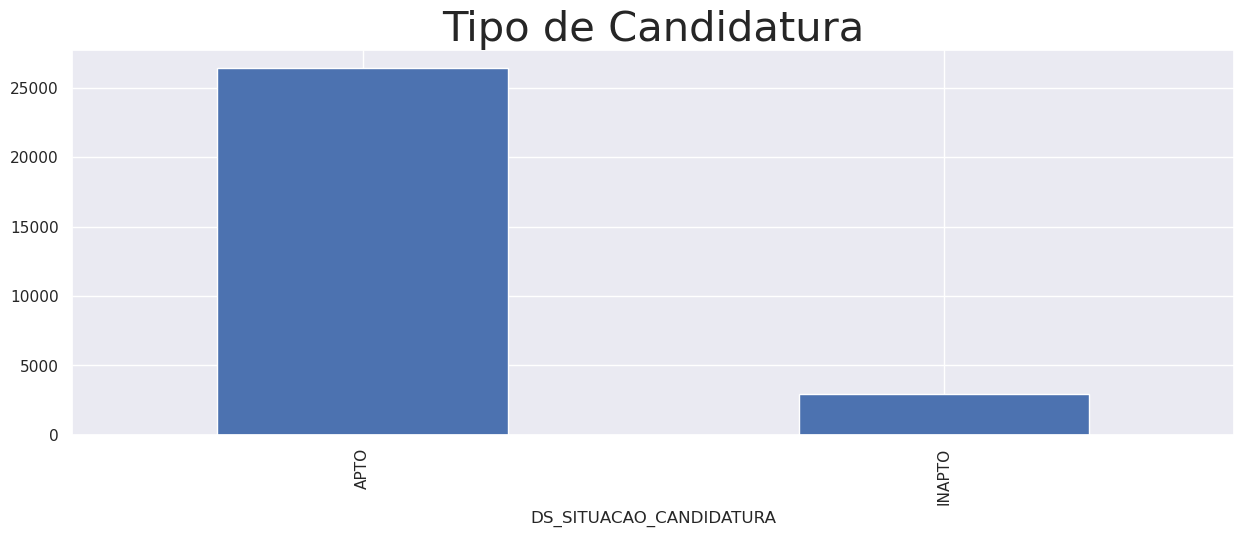

In [69]:
df_bens['DS_SITUACAO_CANDIDATURA'].value_counts().plot(kind='bar', figsize=(15,5))
plt.title('Tipo de Candidatura', fontdict={'fontsize':30});

In [70]:
df_bens = df_bens.query('DS_SITUACAO_CANDIDATURA == "APTO" or DS_SITUACAO_CANDIDATURA == "CADASTRADO"')
df_bens['DS_SITUACAO_CANDIDATURA'].value_counts()

DS_SITUACAO_CANDIDATURA
APTO    26409
Name: count, dtype: int64

In [71]:
df_bens['DS_CARGO'].value_counts()

DS_CARGO
DEPUTADO ESTADUAL     15257
DEPUTADO FEDERAL       9476
DEPUTADO DISTRITAL      571
GOVERNADOR              229
VICE-GOVERNADOR         229
2º SUPLENTE             208
SENADOR                 207
1º SUPLENTE             206
PRESIDENTE               13
VICE-PRESIDENTE          13
Name: count, dtype: int64

###**Candidatos a presidência**

In [72]:
presidente = df_bens.query('DS_CARGO == "PRESIDENTE"')
presidente['DS_CARGO'].value_counts()


DS_CARGO
PRESIDENTE    13
Name: count, dtype: int64

In [73]:
df_bens[df_bens['DS_CARGO'] == "PRESIDENTE"].value_counts()

NM_TIPO_ELEICAO    SG_UE  NM_UE   DS_CARGO    SQ_CANDIDATO  NM_CANDIDATO                         DS_SITUACAO_CANDIDATURA  SG_PARTIDO  DS_GENERO  DS_GRAU_INSTRUCAO            DS_ESTADO_CIVIL  DS_COR_RACA
ELEIÇÃO ORDINÁRIA  BR     BRASIL  PRESIDENTE  280001607829  LUIZ INÁCIO LULA DA SILVA            APTO                     PT          MASCULINO  ENSINO FUNDAMENTAL COMPLETO  CASADO(A)        BRANCA         2
                                              280001618036  JAIR MESSIAS BOLSONARO               APTO                     PL          MASCULINO  SUPERIOR COMPLETO            CASADO(A)        BRANCA         2
                                              280001600167  SOFIA PADUA MANZANO                  APTO                     PCB         FEMININO   SUPERIOR COMPLETO            SOLTEIRO(A)      BRANCA         1
                                              280001602702  LEONARDO PÉRICLES VIEIRA ROQUE       APTO                     UP          MASCULINO  ENSINO MÉDIO COMPLETO       

In [74]:
df_bens.query('DS_CARGO == "PRESIDENTE"')[['NM_CANDIDATO', 'SG_PARTIDO']].sort_values(by='NM_CANDIDATO')

,NM_CANDIDATO,SG_PARTIDO
20248,CIRO FERREIRA GOMES,PDT
2000,JAIR MESSIAS BOLSONARO,PL
5619,JAIR MESSIAS BOLSONARO,PL
20247,JOSE MARIA EYMAEL,DC
27656,KELMON LUIS DA SILVA SOUZA,PTB
27657,LEONARDO PÉRICLES VIEIRA ROQUE,UP
9266,LUIZ FELIPE CHAVES D AVILA,NOVO
16589,LUIZ INÁCIO LULA DA SILVA,PT
23986,LUIZ INÁCIO LULA DA SILVA,PT
1999,SIMONE NASSAR TEBET,MDB


###**Grau de instrução dos candidatos**

Note-se que a grande quantidade dos candidatos possui ensino superior. Isso pode indicar que a qualidade dos governos tende a melhorar por conta do maior grau instrução. 

In [75]:
presidente['DS_GRAU_INSTRUCAO'].value_counts()

DS_GRAU_INSTRUCAO
SUPERIOR COMPLETO              10
ENSINO FUNDAMENTAL COMPLETO     2
ENSINO MÉDIO COMPLETO           1
Name: count, dtype: int64

###**Superior Completo**

In [76]:
presidente.query('DS_GRAU_INSTRUCAO == "SUPERIOR COMPLETO"')['NM_CANDIDATO'].sort_values()

20248                    CIRO FERREIRA GOMES
2000                  JAIR MESSIAS BOLSONARO
5619                  JAIR MESSIAS BOLSONARO
20247                      JOSE MARIA EYMAEL
27656             KELMON LUIS DA SILVA SOUZA
9266              LUIZ FELIPE CHAVES D AVILA
1999                     SIMONE NASSAR TEBET
9265                     SOFIA PADUA MANZANO
27659                SORAYA VIEIRA THRONICKE
27658    VERA LUCIA PEREIRA DA SILVA SALGADO
Name: NM_CANDIDATO, dtype: object

In [77]:
presidente.query('DS_GRAU_INSTRUCAO == "ENSINO FUNDAMENTAL COMPLETO"')['NM_CANDIDATO']

16589    LUIZ INÁCIO LULA DA SILVA
23986    LUIZ INÁCIO LULA DA SILVA
Name: NM_CANDIDATO, dtype: object

In [78]:
presidente.query('DS_GRAU_INSTRUCAO == "ENSINO MÉDIO COMPLETO"')['NM_CANDIDATO']

27657    LEONARDO PÉRICLES VIEIRA ROQUE
Name: NM_CANDIDATO, dtype: object

###**Bens dos candidatos**

Para verificar os bens dos candidatos, acabei tendo que fazer um merge entre duas tabelas

Com estes dados consegui também identificar o tipo de aplicação financeira que cada candidato declarou

In [79]:
patrimonio = presidente.merge(df_cand, how = 'left')

In [80]:
patrimonio.head(3)

,NM_TIPO_ELEICAO,SG_UE,NM_UE,DS_CARGO,SQ_CANDIDATO,NM_CANDIDATO,DS_SITUACAO_CANDIDATURA,SG_PARTIDO,DS_GENERO,DS_GRAU_INSTRUCAO,DS_ESTADO_CIVIL,DS_COR_RACA,ANO_ELEICAO,DS_TIPO_BEM_CANDIDATO,VR_BEM_CANDIDATO
0,ELEIÇÃO ORDINÁRIA,BR,BRASIL,PRESIDENTE,280001607833,SIMONE NASSAR TEBET,APTO,MDB,FEMININO,SUPERIOR COMPLETO,CASADO(A),BRANCA,2022,Apartamento,"81903,69"
1,ELEIÇÃO ORDINÁRIA,BR,BRASIL,PRESIDENTE,280001607833,SIMONE NASSAR TEBET,APTO,MDB,FEMININO,SUPERIOR COMPLETO,CASADO(A),BRANCA,2022,Apartamento,"310000,00"
2,ELEIÇÃO ORDINÁRIA,BR,BRASIL,PRESIDENTE,280001607833,SIMONE NASSAR TEBET,APTO,MDB,FEMININO,SUPERIOR COMPLETO,CASADO(A),BRANCA,2022,Apartamento,"200000,00"


In [81]:
patrimonio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 166 entries, 0 to 165
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   NM_TIPO_ELEICAO          166 non-null    object
 1   SG_UE                    166 non-null    object
 2   NM_UE                    166 non-null    object
 3   DS_CARGO                 166 non-null    object
 4   SQ_CANDIDATO             166 non-null    int64 
 5   NM_CANDIDATO             166 non-null    object
 6   DS_SITUACAO_CANDIDATURA  166 non-null    object
 7   SG_PARTIDO               166 non-null    object
 8   DS_GENERO                166 non-null    object
 9   DS_GRAU_INSTRUCAO        166 non-null    object
 10  DS_ESTADO_CIVIL          166 non-null    object
 11  DS_COR_RACA              166 non-null    object
 12  ANO_ELEICAO              166 non-null    int64 
 13  DS_TIPO_BEM_CANDIDATO    166 non-null    object
 14  VR_BEM_CANDIDATO         166 non-null    o

In [82]:
patrimonio['VR_BEM_CANDIDATO'] = patrimonio['VR_BEM_CANDIDATO'].apply(lambda x: float(x.replace(',', '.')))

In [83]:
patrimonio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 166 entries, 0 to 165
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   NM_TIPO_ELEICAO          166 non-null    object 
 1   SG_UE                    166 non-null    object 
 2   NM_UE                    166 non-null    object 
 3   DS_CARGO                 166 non-null    object 
 4   SQ_CANDIDATO             166 non-null    int64  
 5   NM_CANDIDATO             166 non-null    object 
 6   DS_SITUACAO_CANDIDATURA  166 non-null    object 
 7   SG_PARTIDO               166 non-null    object 
 8   DS_GENERO                166 non-null    object 
 9   DS_GRAU_INSTRUCAO        166 non-null    object 
 10  DS_ESTADO_CIVIL          166 non-null    object 
 11  DS_COR_RACA              166 non-null    object 
 12  ANO_ELEICAO              166 non-null    int64  
 13  DS_TIPO_BEM_CANDIDATO    166 non-null    object 
 14  VR_BEM_CANDIDATO         1

In [84]:
total = patrimonio['VR_BEM_CANDIDATO'].sum().round(2)
total

np.float64(57337063.07)

Aqui vale uma observação. O candidato a deputado federal que tem o maior patrimônio, supera a soma de todos os candidatos à presidência da república juntos.

In [85]:
dados = patrimonio.groupby(['NM_CANDIDATO'])['VR_BEM_CANDIDATO'].sum().sort_values(ascending=False).reset_index()
dados['VR_BEM_CANDIDATO'] = dados['VR_BEM_CANDIDATO'].apply(lambda x: f'R$ {x:,.2f}'.replace(',', ' ').replace('.', ',').replace('  ', '.'))
dados

,NM_CANDIDATO,VR_BEM_CANDIDATO
0,LUIZ FELIPE CHAVES D AVILA,"R$ 24 619 627,66"
1,LUIZ INÁCIO LULA DA SILVA,"R$ 14 847 451,56"
2,JOSE MARIA EYMAEL,"R$ 6 572 826,60"
3,JAIR MESSIAS BOLSONARO,"R$ 4 635 109,46"
4,CIRO FERREIRA GOMES,"R$ 3 039 761,97"
5,SIMONE NASSAR TEBET,"R$ 2 323 735,38"
6,SORAYA VIEIRA THRONICKE,"R$ 783 000,00"
7,SOFIA PADUA MANZANO,"R$ 498 000,00"
8,VERA LUCIA PEREIRA DA SILVA SALGADO,"R$ 8 805,00"
9,KELMON LUIS DA SILVA SOUZA,"R$ 8 548,13"


In [86]:
patrimonio['DS_TIPO_BEM_CANDIDATO'].value_counts().head(10)

DS_TIPO_BEM_CANDIDATO
Depósito bancário em conta corrente no País                     21
Apartamento                                                     19
Casa                                                            18
Quotas ou quinhões de capital                                   15
Caderneta de poupança                                           13
Terreno                                                         12
Veículo automotor terrestre: caminhão, automóvel, moto, etc.    12
Crédito decorrente de empréstimo                                 9
Ações (inclusive as provenientes de linha telefônica)            6
Dinheiro em espécie - moeda nacional                             4
Name: count, dtype: int64

In [87]:
def extrato_investimento(candidato):
    temp = patrimonio.query('NM_CANDIDATO == @candidato').groupby(['DS_TIPO_BEM_CANDIDATO']).sum().sort_values(by='VR_BEM_CANDIDATO', ascending=False).reset_index()[['DS_TIPO_BEM_CANDIDATO', 'VR_BEM_CANDIDATO']]
    
    total = temp['VR_BEM_CANDIDATO'].sum()
    print(f'R$ {total:,.2f}')
    temp['VR_BEM_CANDIDATO'] = temp['VR_BEM_CANDIDATO'].apply(lambda x: f'R$ {x:,.2f}'.replace(',', ' ').replace('.', ',').replace('  ', '.'))
    return temp

In [88]:
extrato_investimento('LUIZ FELIPE CHAVES D AVILA')

R$ 24,619,627.66


,DS_TIPO_BEM_CANDIDATO,VR_BEM_CANDIDATO
0,Quotas ou quinhões de capital,"R$ 21 031 213,62"
1,Casa,"R$ 3 348 515,20"
2,"Aplicação de renda fixa (CDB, RDB e outros)","R$ 238 578,79"
3,Outras aplicações e Investimentos,"R$ 1 320,05"


In [89]:
extrato_investimento('LUIZ INÁCIO LULA DA SILVA')

R$ 14,847,451.56


,DS_TIPO_BEM_CANDIDATO,VR_BEM_CANDIDATO
0,VGBL - Vida Gerador de Benefício Livre,"R$ 11 141 597,98"
1,OUTROS BENS E DIREITOS,"R$ 860 041,98"
2,Terreno,"R$ 795 466,90"
3,Crédito decorrente de empréstimo,"R$ 500 000,00"
4,Construção,"R$ 493 837,64"
5,"Aplicação de renda fixa (CDB, RDB e outros)","R$ 371 489,62"
6,"Veículo automotor terrestre: caminhão, automóv...","R$ 266 950,00"
7,Apartamento,"R$ 265 811,86"
8,Quotas ou quinhões de capital,"R$ 98 000,00"
9,Depósito bancário em conta corrente no País,"R$ 41 724,46"


###**Candidatos deputado federal**

####**Candidatos a deputado federal por partido**

O partido republicanos é o partido que possui o maior número de candidatos

Também podemos observar que todos os partidos possuem um número muito parecido de candidatos

In [90]:
deputados = df_bens.query('DS_CARGO == "DEPUTADO FEDERAL"')
deputados.groupby(['SG_PARTIDO']).size().sort_values(ascending=False).head(20)

SG_PARTIDO
REPUBLICANOS     505
UNIÃO            482
PL               476
PODE             476
PP               476
MDB              464
PTB              462
PDT              448
PATRIOTA         430
PSB              420
PSD              399
PSC              390
AVANTE           389
SOLIDARIEDADE    364
PT               357
PROS             312
AGIR             310
PSOL             297
PSDB             291
PRTB             286
dtype: int64

####**Candidatos por <font style = 'color:blue'>gênero por partido</font>**

Apenas 34% dos candidatos é do sexo feminino

Quantidade em número absolutos
       QUANTIDADE  count
0       MASCULINO   6128
1        FEMININO   3346
2  NÃO DIVULGÁVEL      2

Quantidade em percentual
       QUANTIDADE  proportion
0       MASCULINO   64.668637
1        FEMININO   35.310257
2  NÃO DIVULGÁVEL    0.021106



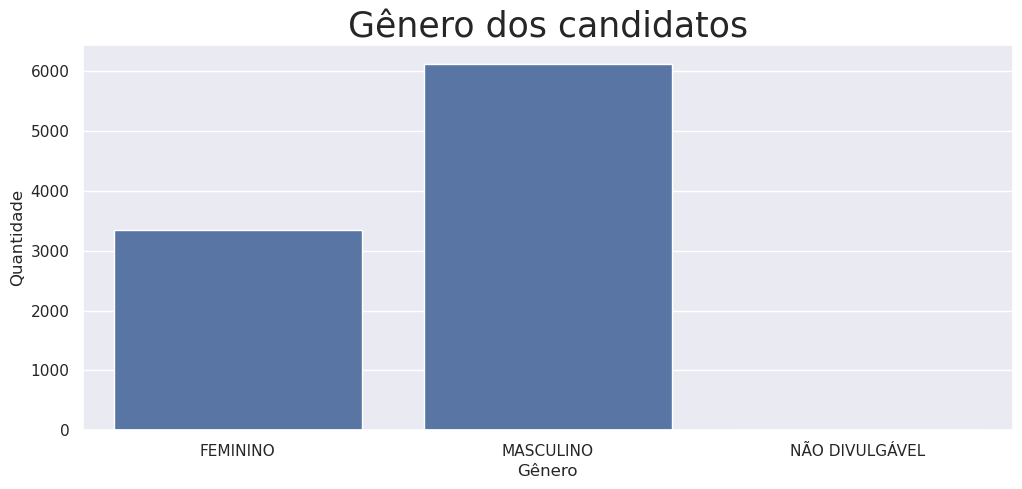

In [ ]:
#from locale import normalize
imagem = sns.countplot(data=deputados, x='DS_GENERO')
imagem.set_ylabel('Quantidade', fontsize=12);
imagem.set_xlabel('Gênero')
imagem.set_title('Gênero dos candidatos', fontsize=25)
imagem.figure.set_size_inches(12,5)

print('Quantidade em número absolutos')
dados = deputados['DS_GENERO'].value_counts().reset_index()
dados.rename(columns = {'index':'GENERO', 'DS_GENERO': 'QUANTIDADE'}, inplace=True)
print(dados)
print()

print('Quantidade em percentual')
dados1 = deputados['DS_GENERO'].value_counts(normalize=True) * 100
dados1 = dados1.reset_index()
dados1.rename(columns={'index':'GENERO', 'DS_GENERO':'QUANTIDADE'}, inplace=True)
dados1['QUANTIDADE'] = round(dados1['QUANTIDADE'],2)
print(dados1)
print()

####**Candidatos sexo <font style='color:red'>Feminino</font> por partido**

In [93]:
feminino = deputados.query('DS_GENERO == "FEMININO"')
temp = feminino['SG_PARTIDO'].value_counts().reset_index().head(5)
temp.rename(columns={'index':'PARTIDO'}, inplace=True)

imagem = sns.barplot(data=temp, x = 'SG_PARTIDO', y='PARTIDO')
imagem.set_ylabel('Partido', fontsize = 12);
imagem.set_xlabel('Quantidade')
imagem.set_title('Candidatas femininos por partido', fontsize=25)
imagem.figure.set_size_inches(12,5)

temp

ValueError: Could not interpret value `PARTIDO` for `y`. An entry with this name does not appear in `data`.

In [94]:
feminino.head(3)

,NM_TIPO_ELEICAO,SG_UE,NM_UE,DS_CARGO,SQ_CANDIDATO,NM_CANDIDATO,DS_SITUACAO_CANDIDATURA,SG_PARTIDO,DS_GENERO,DS_GRAU_INSTRUCAO,DS_ESTADO_CIVIL,DS_COR_RACA
35,ELEIÇÃO ORDINÁRIA,MA,MARANHÃO,DEPUTADO FEDERAL,100001713830,ESMERALDA LACERDA ARAUJO FRANÇA,APTO,REDE,FEMININO,ENSINO MÉDIO COMPLETO,CASADO(A),PARDA
37,ELEIÇÃO ORDINÁRIA,MA,MARANHÃO,DEPUTADO FEDERAL,100001723427,ANTONIA SANTOS,APTO,PRTB,FEMININO,ENSINO FUNDAMENTAL COMPLETO,SOLTEIRO(A),PARDA
130,ELEIÇÃO ORDINÁRIA,MA,MARANHÃO,DEPUTADO FEDERAL,100001599083,ROSA CARVALHO MESQUITA,APTO,MDB,FEMININO,ENSINO MÉDIO COMPLETO,CASADO(A),PRETA
